# Histogram-binning native intervals

Quantile bins on the mean of the last 5 lagged returns; intervals are empirical α/2 and 1−α/2 quantiles of the bin's training labels.  See `src/analysis/Simple_Native/README.md`.

**Workflow.** This notebook (i) runs `hist_binning` on every `(ticker, regime)` cell — *idempotently*, skipping cells whose CSV already exists in `results/`; (ii) loads those CSVs and writes a per-cell timeline figure into `report/figures/timelines/Simple_Native/`; (iii) prints a per-cell metrics table and a summary.

In [1]:
# sys.path bootstrap so 'from src...' works regardless of CWD
import sys, pathlib
ROOT = pathlib.Path.cwd()
while not (ROOT / "requirements.txt").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("project root:", ROOT)


project root: /home/jsarin/conformalQuant


In [2]:
import warnings, glob, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

from src.analysis._shared import (
    RESULTS_DIR, CRISIS_WINDOWS, MODEL_CATEGORIES,
    ensure_data, iterate_experiments, walk_forward, save_intervals, make_wrapper,
)
from src.plotting import plot_interval_timeline, compute_cell_metrics, render_cell_grid

FORCE_RERUN = False  # set True to ignore cached CSVs and re-run every cell


## 1. Run `hist_binning` (idempotent — set `FORCE_RERUN = True` to override)

In [3]:
from src.conformal.hist_binning_native import HistogramBinningNative
data = ensure_data()
print(f"data: {len(data):,} rows  |  {data.index.min().date()} -> {data.index.max().date()}")

MODEL_NAME = "hist_binning"
WRAPPERS = ["native"]
print(f"\nRunning {MODEL_NAME} on every (ticker, regime) cell ...")

for split in iterate_experiments():
    out = RESULTS_DIR / f"{MODEL_NAME}_native_{split.ticker.value}_{split.regime}.csv"
    if out.exists() and not FORCE_RERUN:
        print(f"  cached  {split.regime} {split.ticker.value}")
        continue
    train = split.slice_train(data); calib = split.slice_calib(data); full = split.slice_full(data)
    if len(train) < 60:
        print(f"  skip {split.regime} {split.ticker.value} — only {len(train)} train rows")
        continue
    t0 = time.perf_counter()
    try:
        m = HistogramBinningNative(label_col_name=split.label_col, num_lags=5, confidence_level=0.90)
        m.fit_and_calibrate(train, calib)
        intervals = walk_forward(m, full, split.test_start, split.test_end)
        save_intervals(intervals, MODEL_NAME, "native", split.ticker, split.regime)
        cell = compute_cell_metrics(intervals)
        print(f"  {split.regime} {split.ticker.value:5s}: "
              f"cov={cell['cov']:.3f}  W={cell['winkler']:.3f}  width={cell['width']:.4f}  "
              f"({time.perf_counter()-t0:.1f}s)")
    except Exception as e:
        print(f"  {split.regime} {split.ticker.value:5s}: SKIPPED ({type(e).__name__}: {e})")
        if out.exists(): out.unlink()


data: 5,863 rows  |  2003-01-03 -> 2026-04-23

Running hist_binning on every (ticker, regime) cell ...


  2008 AIG  : cov=0.364  W=0.992  width=0.0598  (0.2s)


  2008 GNW  : cov=0.403  W=0.988  width=0.0622  (0.2s)


  2008 MGM  : cov=0.423  W=0.722  width=0.0625  (0.3s)
  2020 MCD  : cov=0.786  W=0.121  width=0.0322  (0.2s)


  2020 MGM  : cov=0.714  W=0.309  width=0.0667  (0.2s)
  2020 AZO  : cov=0.799  W=0.126  width=0.0397  (0.2s)


  2022 SNAP : cov=0.806  W=0.272  width=0.1067  (0.3s)


  2022 NFLX : cov=0.852  W=0.158  width=0.0793  (0.3s)


  2022 META : cov=0.760  W=0.166  width=0.0616  (0.3s)


## 2. Render timeline figures, one per cell

In [4]:
CATEGORY = "Simple_Native"
MODEL_NAME = "hist_binning"
import pathlib
out_dir = ROOT / "report" / "figures" / "timelines" / CATEGORY
patterns = [str(RESULTS_DIR / f"{MODEL_NAME}_*_*.csv")]
files = sorted({f for p in patterns for f in glob.glob(p)})
files = [f for f in files if pathlib.Path(f).name.startswith(f"{MODEL_NAME}_")]
if not files:
    raise RuntimeError(f"no CSVs for model={MODEL_NAME!r}; did the run cell finish?")
raw = pd.concat([pd.read_csv(f, parse_dates=["date"]) for f in files], ignore_index=True)
raw = raw[raw["model"] == MODEL_NAME]
metrics = render_cell_grid(
    raw, model_filter=[MODEL_NAME], out_dir=out_dir,
    crisis_windows=CRISIS_WINDOWS, category_lookup=MODEL_CATEGORIES,
)
print(f"wrote {len(metrics)} timeline figures → {out_dir.relative_to(ROOT)}")
metrics_sorted = metrics.sort_values(["wrapper", "regime", "ticker"]).reset_index(drop=True)
display(metrics_sorted.round(3))


wrote 9 timeline figures → report/figures/timelines/Simple_Native


,model,wrapper,ticker,regime,cov,winkler,width,n
0,hist_binning,native,AIG,2008,0.364,0.992,0.060,390
1,hist_binning,native,GNW,2008,0.403,0.988,0.062,390
2,hist_binning,native,MGM,2008,0.423,0.722,0.062,390
3,hist_binning,native,AZO,2020,0.799,0.126,0.040,304
4,hist_binning,native,MCD,2020,0.786,0.121,0.032,304
5,hist_binning,native,MGM,2020,0.714,0.309,0.067,304
6,hist_binning,native,META,2022,0.760,0.166,0.062,501
7,hist_binning,native,NFLX,2022,0.852,0.158,0.079,501
8,hist_binning,native,SNAP,2022,0.806,0.272,0.107,501


## 3. Summary aggregated across (ticker, regime)


hist_binning — average across all 9 (ticker, regime) cells (lower Winkler = better)


,cov,winkler,width
wrapper,,,
native,0.656,0.428,0.063



Representative figure (hist_binning_native_AIG_2008.png):


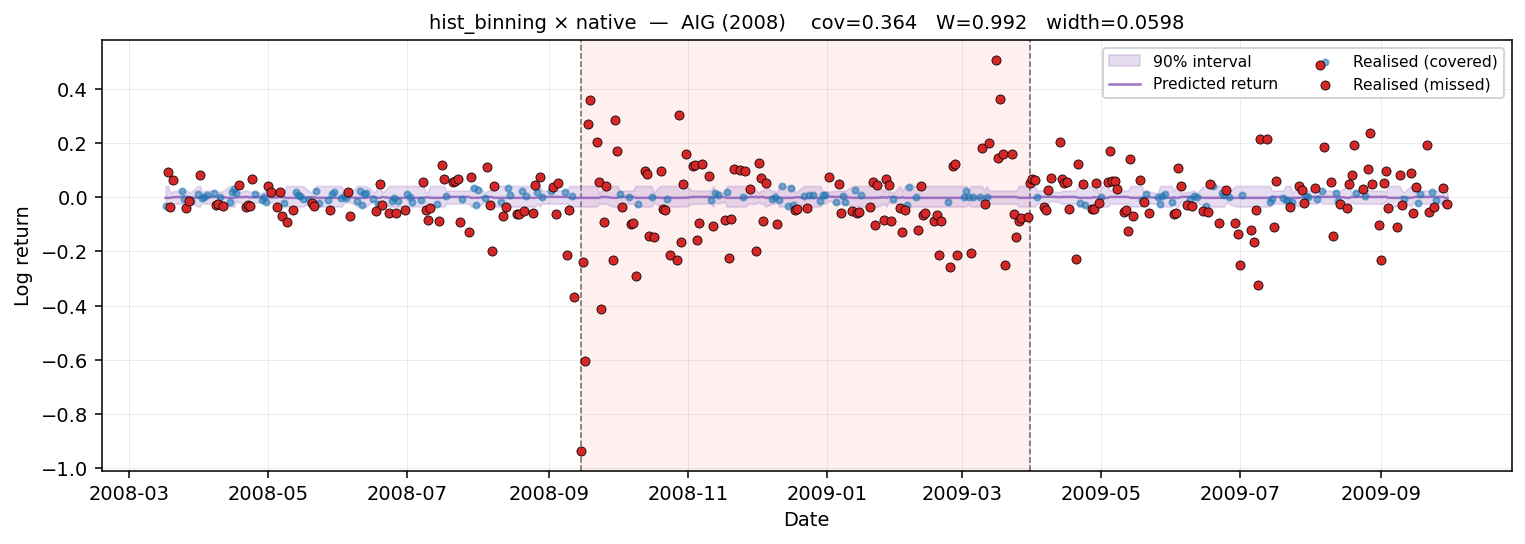

In [5]:
# Aggregate by wrapper — mean across all (ticker, regime) cells
summary = (
    metrics_sorted
    .groupby("wrapper")[["cov", "winkler", "width"]]
    .mean()
    .sort_values("winkler")
    .round(3)
)
print(f"\n{MODEL_NAME} — average across all 9 (ticker, regime) cells (lower Winkler = better)")
display(summary)

# Show one representative figure inline
sample = sorted((ROOT / "report" / "figures" / "timelines" / CATEGORY).glob(f"{MODEL_NAME}_*.png"))
if sample:
    print(f"\nRepresentative figure ({sample[0].name}):")
    display(Image(filename=str(sample[0])))
